In [1]:
#H&E 20X pathces synthesize SHG fibers

import os
from pathlib import Path

# 1. Set this to your actual workflow folder
workflow_dir = Path(r"C:\Users\Liyua\3945041\uw-loci\he_shg_synth_workflow-v0.1.0\uw-loci-he_shg_synth_workflow-fcf9bd5")
os.chdir(workflow_dir)
print("Working directory:", os.getcwd())

# 2. Confirm the input folder name
input_folder = "input_test_AABK"
input_path = workflow_dir / input_folder
if not input_path.exists():
    raise FileNotFoundError(f"Could not find: {input_path}")
print("Found input folder, contains:", [f.name for f in input_path.iterdir()])

# 3. Run the synthesis 
#    This uses the repo defaults: it expects 'input_test_<input_folder>' internally,
#    but passing --input-folder points it to your folder name.
!python main.py --input-folder {input_folder} --use-cuda 0

# 4. Inspect the output
output_folder = Path(f"output_test_{input_folder}")
if output_folder.exists():
    print("Output files:", [f.name for f in output_folder.iterdir()])
else:
    print("No output directory created.")


Working directory: C:\Users\Liyua\3945041\uw-loci\he_shg_synth_workflow-v0.1.0\uw-loci-he_shg_synth_workflow-fcf9bd5
Found input folder, contains: ['patch_0000.png', 'patch_0008.png', 'patch_0009.png', 'patch_0010.png', 'patch_0011.png', 'patch_0013.png', 'patch_0014.png', 'patch_0016.png', 'patch_0017.png']
use CPU
Fiji disabled. Will save stitched output directly.
Processing: patch_0000.png
Saved: output_test_AABK\shg_patch_0000.png
Processing: patch_0008.png
Saved: output_test_AABK\shg_patch_0008.png
Processing: patch_0009.png
Saved: output_test_AABK\shg_patch_0009.png
Processing: patch_0010.png
Saved: output_test_AABK\shg_patch_0010.png
Processing: patch_0011.png
Saved: output_test_AABK\shg_patch_0011.png
Processing: patch_0013.png
Saved: output_test_AABK\shg_patch_0013.png
Processing: patch_0014.png
Saved: output_test_AABK\shg_patch_0014.png
Processing: patch_0016.png
Saved: output_test_AABK\shg_patch_0016.png
Processing: patch_0017.png
Saved: output_test_AABK\shg_patch_0017.png
N

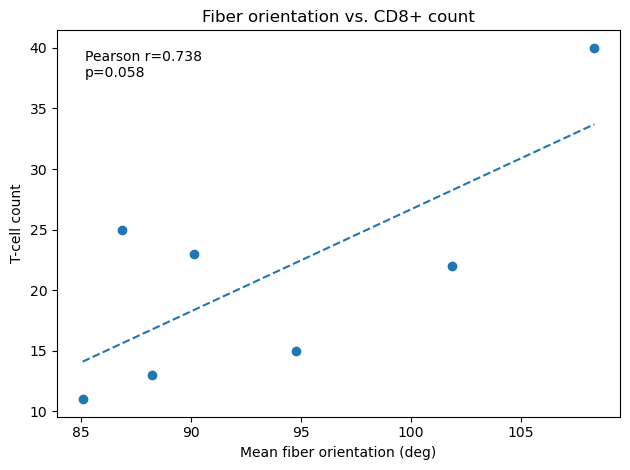

Spearman ρ = 0.536, p = 0.215


C:\Users\Liyua\AppData\Local\Temp\ipykernel_13932\468145737.py:41: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  boot_corrs.append(pearsonr(x[idx], y[idx])[0])


95% CI for r: [-0.307, 0.974]


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

# assume x,y and r,p are already defined
# x = df[["mean_orient_deg"]].values.flatten()
# y = df["tcell_count"].values

# 1) Scatter + regression line + annotate
fig, ax = plt.subplots()
ax.scatter(x, y)

# 1) Make sure df is populated, then drop any NaNs
df2 = df.dropna(subset=["mean_orient_deg","tcell_count"])

# 2) Extract 1‑D Series, not a DataFrame slice
x = df2["mean_orient_deg"]        # this is a pandas Series → 1D
y = df2["tcell_count"]
# best-fit line
m, b = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, m*xs + b, linestyle='--')
ax.set_xlabel("Mean fiber orientation (deg)")
ax.set_ylabel("T-cell count")
ax.set_title("Fiber orientation vs. CD8+ count")
ax.text(0.05, 0.95, f"Pearson r={r:.3f}\np={p:.3f}",
        transform=ax.transAxes, va='top')
plt.tight_layout()
plt.show()

# 2) Spearman rank-correlation
rho, p_s = spearmanr(x, y)
print(f"Spearman ρ = {rho:.3f}, p = {p_s:.3f}")

# 3) Bootstrap 95% CI for Pearson r
n_boot = 1000
boot_corrs = []
rng = np.random.default_rng(0)
for _ in range(n_boot):
    idx = rng.choice(len(x), len(x), replace=True)
    boot_corrs.append(pearsonr(x[idx], y[idx])[0])
ci_lower, ci_upper = np.percentile(boot_corrs, [2.5, 97.5])
print(f"95% CI for r: [{ci_lower:.3f}, {ci_upper:.3f}]")
